# 4. Ingeniería de características

**Objetivo:** comprobar si una representación geométrica mejora la predicción de `First_Failure_Load_N` [N], la fuerza de primera rotura de una fibra o un pivote. Se construyen las variables, se comparan A/B/C/D con el mismo modelo y se examinan sus errores fuera de muestra.

[Variables y unidades](../docs/diccionario_datos.md#consulta-rápida) · [Fórmulas](../docs/diccionario_features.md) · [Protocolo](../docs/feature_engineering.md)

## 4.1 Datos de entrada e hipótesis

La tabla curada conserva la geometría previa al ensayo y el target observado. `Case_n` permite rastrear resultados; no entra al modelo. Las fuerzas, desplazamientos y energías posteriores al ensayo quedan fuera de los predictores.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/experimentos_fe.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.experimentos_fe import run, load_dataset
from src.feature_engineering import (
    GEOMETRY, TARGET, MOMENTS, LOG_RATIO, GeometryRepresentation,
    make_pipeline, feature_names, nominal_groups,
)

config = json.loads((ROOT / 'config/feature_engineering.json').read_text(encoding='utf-8'))
frame = load_dataset(ROOT, config)
X, y = frame[GEOMETRY].copy(), frame[TARGET].copy()
assert TARGET not in X and 'Case_n' not in X

def show_table(data, decimals=4):
    display(data.style.hide(axis='index').format(precision=decimals, na_rep='—'))

show_table(pd.DataFrame([
    ['Entradas', ', '.join(X.columns)],
    ['Target / unidad', f'{TARGET} / {config["target_unit"]}'],
    ['Agrupación principal', ' + '.join(config['group_columns'])],
    ['Modelo fijo', f'Ridge, alpha={config["model"]["alpha"]}, solver=SVD'],
], columns=['Contrato', 'Contenido']))

Contrato,Contenido
Entradas,"n_cells_Y, Fiber_height, Fiber_base, Fiber_total_length, Fiber_total_volume, Pivot_height, Pivot_radius, Pivot_total_number, Pivot_total_volume, Sample_total_volume"
Target / unidad,First_Failure_Load_N / N
Agrupación principal,n_cells_Y + Fiber_height + Pivot_height
Modelo fijo,"Ridge, alpha=1.0, solver=SVD"


In [2]:
hypotheses = pd.DataFrame([
    ['B − A', 'Dos momentos de sección', 'b·h³/12 y h·b³/12 [mm⁴]',
     'Representar la forma de la fibra; aporte predictivo por comprobar'],
    ['C − B', 'Razón logarítmica', 'ln(Vp/Vf) [sin unidad]',
     'Asociación del EDA que cambia al condicionar por familia'],
    ['D − C', 'Retirada de tres columnas', 'Longitud de fibras, cantidad de pivotes y volumen de fibras',
     'Arquitectura repetida y volúmenes complementarios'],
], columns=['Comparación', 'Intervención', 'Operación', 'Hipótesis del EDA'])
show_table(hypotheses)
display(Markdown('[Matriz de evidencia EDA → características](../reports/feature_engineering/tables/matriz_eda_fe.csv).'))

Comparación,Intervención,Operación,Hipótesis del EDA
B − A,Dos momentos de sección,b·h³/12 y h·b³/12 [mm⁴],Representar la forma de la fibra; aporte predictivo por comprobar
C − B,Razón logarítmica,ln(Vp/Vf) [sin unidad],Asociación del EDA que cambia al condicionar por familia
D − C,Retirada de tres columnas,"Longitud de fibras, cantidad de pivotes y volumen de fibras",Arquitectura repetida y volúmenes complementarios


[Matriz de evidencia EDA → características](../reports/feature_engineering/tables/matriz_eda_fe.csv).

## 4.2 Construcción y comprobación de características

Se toma el primer caso por identificador, sin seleccionarlo por su respuesta. `b` y `h` son la base y altura de la fibra; `Vp` y `Vf`, los volúmenes de pivotes y fibras. Los momentos describen una sección rectangular ideal: no son rigidez medida ni resistencia a rotura.

In [3]:
case_id = int(frame.iloc[0].Case_n)
example = X.iloc[[0]].copy()
b, h = example.iloc[0][['Fiber_base', 'Fiber_height']]
vp, vf = example.iloc[0][['Pivot_total_volume', 'Fiber_total_volume']]
manual = np.array([b * h**3 / 12, h * b**3 / 12, np.log(vp / vf)])

# Transformación por fila: no aprende medias ni utiliza la respuesta.
derived_example = GeometryRepresentation('C').fit_transform(example)
computed = derived_example[MOMENTS + [LOG_RATIO]].iloc[0].to_numpy()
np.testing.assert_allclose(computed, manual, rtol=1e-12)

show_table(pd.DataFrame({
    'Característica': MOMENTS + [LOG_RATIO],
    'Sustitución con geometría real': [
        f'{b:g} × {h:g}³ / 12', f'{h:g} × {b:g}³ / 12', f'ln({vp:g} / {vf:g})'],
    'Valor calculado': manual,
    'Unidad': ['mm⁴', 'mm⁴', 'sin unidad'],
    'Coincide con el transformador': np.isclose(computed, manual),
}))
display(Markdown(f'**Caso {case_id}:** el cálculo manual y el transformador coinciden.'))

Característica,Sustitución con geometría real,Valor calculado,Unidad,Coincide con el transformador
I_fibra_bh3_mm4,2.4 × 1³ / 12,0.2000,mm⁴,True
I_fibra_hb3_mm4,1 × 2.4³ / 12,1.1520,mm⁴,True
log_volumen_pivotes_sobre_fibras,ln(88.71 / 6435.3),-4.2842,sin unidad,True


**Caso 1:** el cálculo manual y el transformador coinciden.

In [4]:
# Diagnóstico del dominio observado. El escalamiento se ajustará después, solo en train.
represented = GeometryRepresentation('C').fit_transform(X)
derived = represented[MOMENTS + [LOG_RATIO]]
assert (X[['Fiber_base', 'Fiber_height', 'Pivot_total_volume', 'Fiber_total_volume']] > 0).all().all()
assert np.isfinite(derived.to_numpy()).all()
diagnostic = derived.agg(['min', 'median', 'max']).T.rename(
    columns={'min': 'Mínimo', 'median': 'Mediana', 'max': 'Máximo'})
diagnostic['Valores distintos'] = derived.nunique()
show_table(diagnostic.rename_axis('Característica').reset_index())
display(Markdown('Dominio positivo y transformaciones finitas comprobados. Un logaritmo negativo indica Vp < Vf; no representa un volumen negativo.'))

Característica,Mínimo,Mediana,Máximo,Valores distintos
I_fibra_bh3_mm4,0.1175,0.2405,0.3910,20
I_fibra_hb3_mm4,0.2336,0.5582,1.1520,20
log_volumen_pivotes_sobre_fibras,-4.2842,-3.6763,-3.1624,9


Dominio positivo y transformaciones finitas comprobados. Un logaritmo negativo indica Vp < Vf; no representa un volumen negativo.

## 4.3 Pipeline y ejecución del experimento

Contrato de entradas → imputación de contingencia → fórmulas → filtro de varianza → estandarización → Ridge. Cada entrenamiento aprende sus propias medianas, columnas constantes, medias y escalas. A/B/C/D comparten particiones y parámetros; el control `Dummy` predice la media del entrenamiento.

In [5]:
display(make_pipeline('B', alpha=config['model']['alpha']))
summary = run(ROOT)
OUT = ROOT / 'reports/feature_engineering'

def table(name):
    return pd.read_csv(OUT / 'tables' / f'{name}.csv')

captions = {c['file']: c for c in json.loads((OUT / 'leyendas.json').read_text(encoding='utf-8'))}
def show_figure(name):
    caption = captions[name]
    display(Markdown('### ' + caption['title']))
    display(Image(filename=str(OUT / 'figures' / (name + '.png')), width=1000))
    display(Markdown(caption['interpretation']))

predictions = table('predicciones_oof')
folds = table('metricas_folds')
primary = summary.loc[summary.protocolo == 'configuracion'].set_index('experimento')
secondary = summary.loc[summary.protocolo == 'familia'].set_index('experimento')
display(Markdown('Ejecución completada. Se guardaron predicciones OOF, particiones y estadísticas de cada entrenamiento.'))

,steps,"[('contract', ...), ('imputer', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,True
,variant,'B'


Ejecución completada. Se guardaron predicciones OOF, particiones y estadísticas de cada entrenamiento.

## 4.4 Representaciones y redundancia

Se distingue la retirada de una columna constante, aprendida en cada entrenamiento, de la reducción fijada para D. El rango caracteriza la dependencia lineal de las columnas transformadas; no es una métrica de precisión.

### Figura 1. Variables que llegan a cada experimento

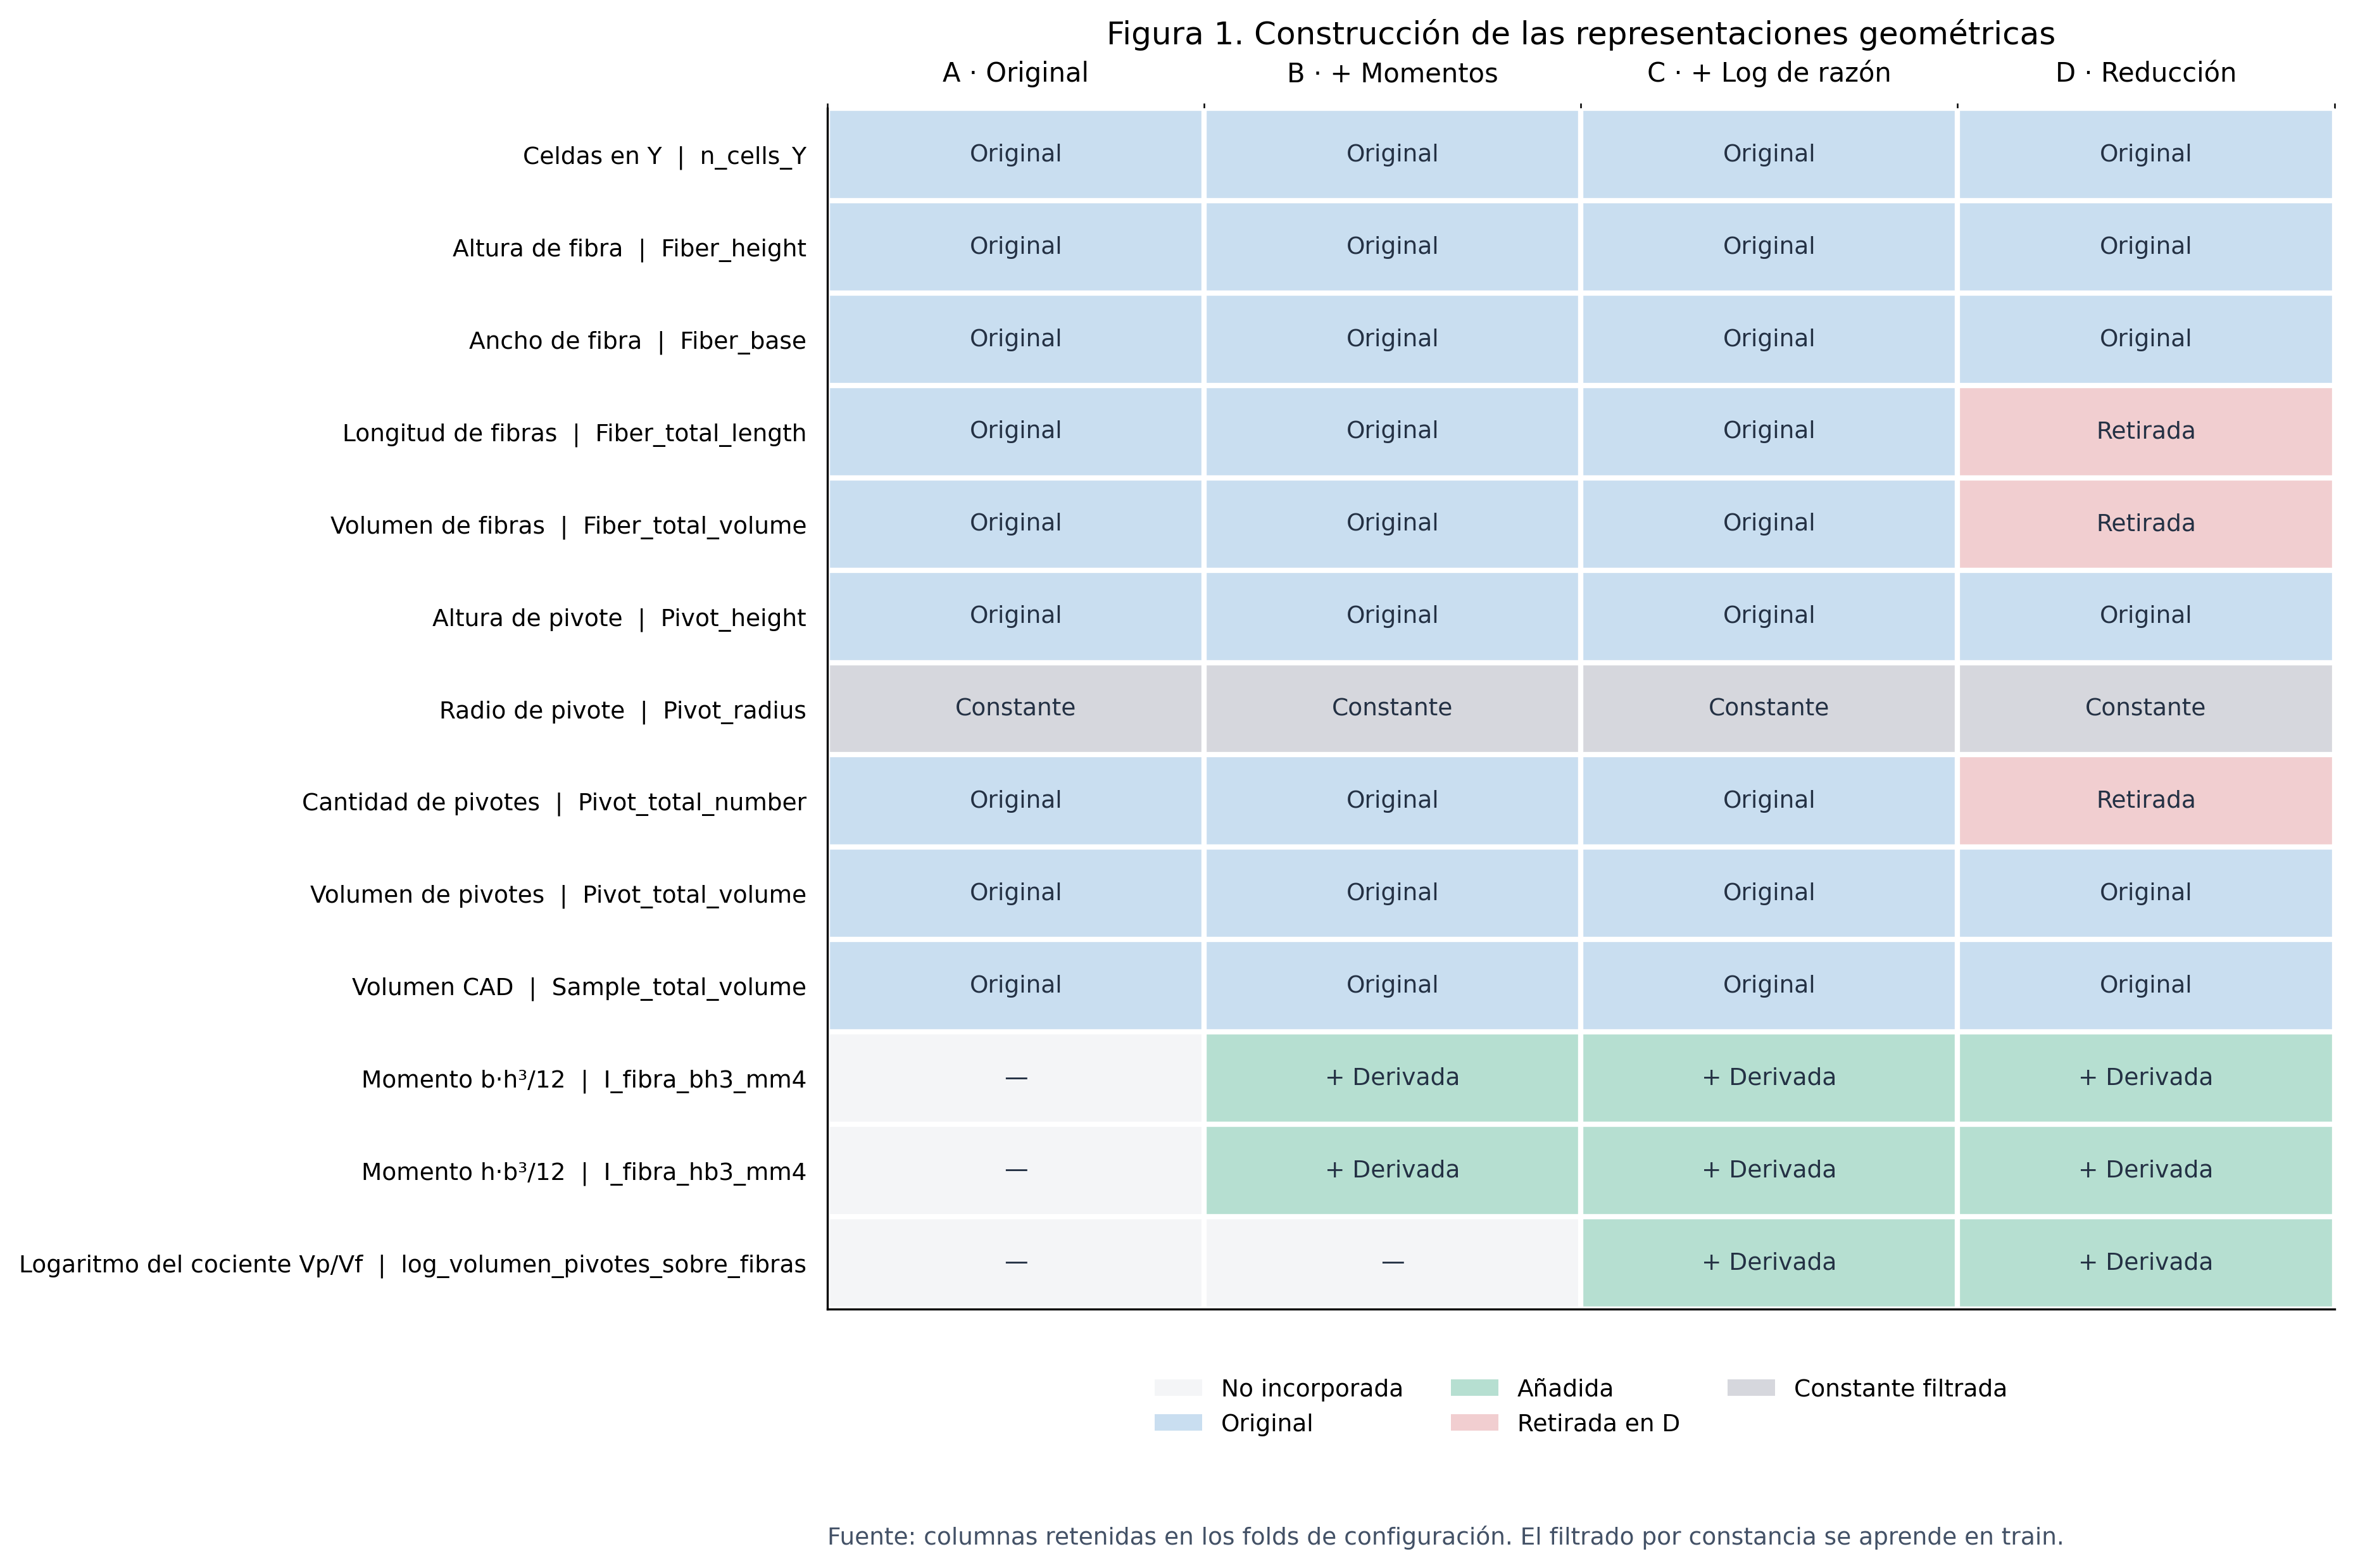

El filtro de varianza retira el radio constante dentro de cada entrenamiento. D retira además tres columnas por hipótesis geométrica; el volumen de fibras sigue interviniendo en la razón logarítmica. Añadir columnas no añade mediciones.

In [6]:
show_figure('FE06_representaciones')

### Figura 2. Dimensión y rango de la representación

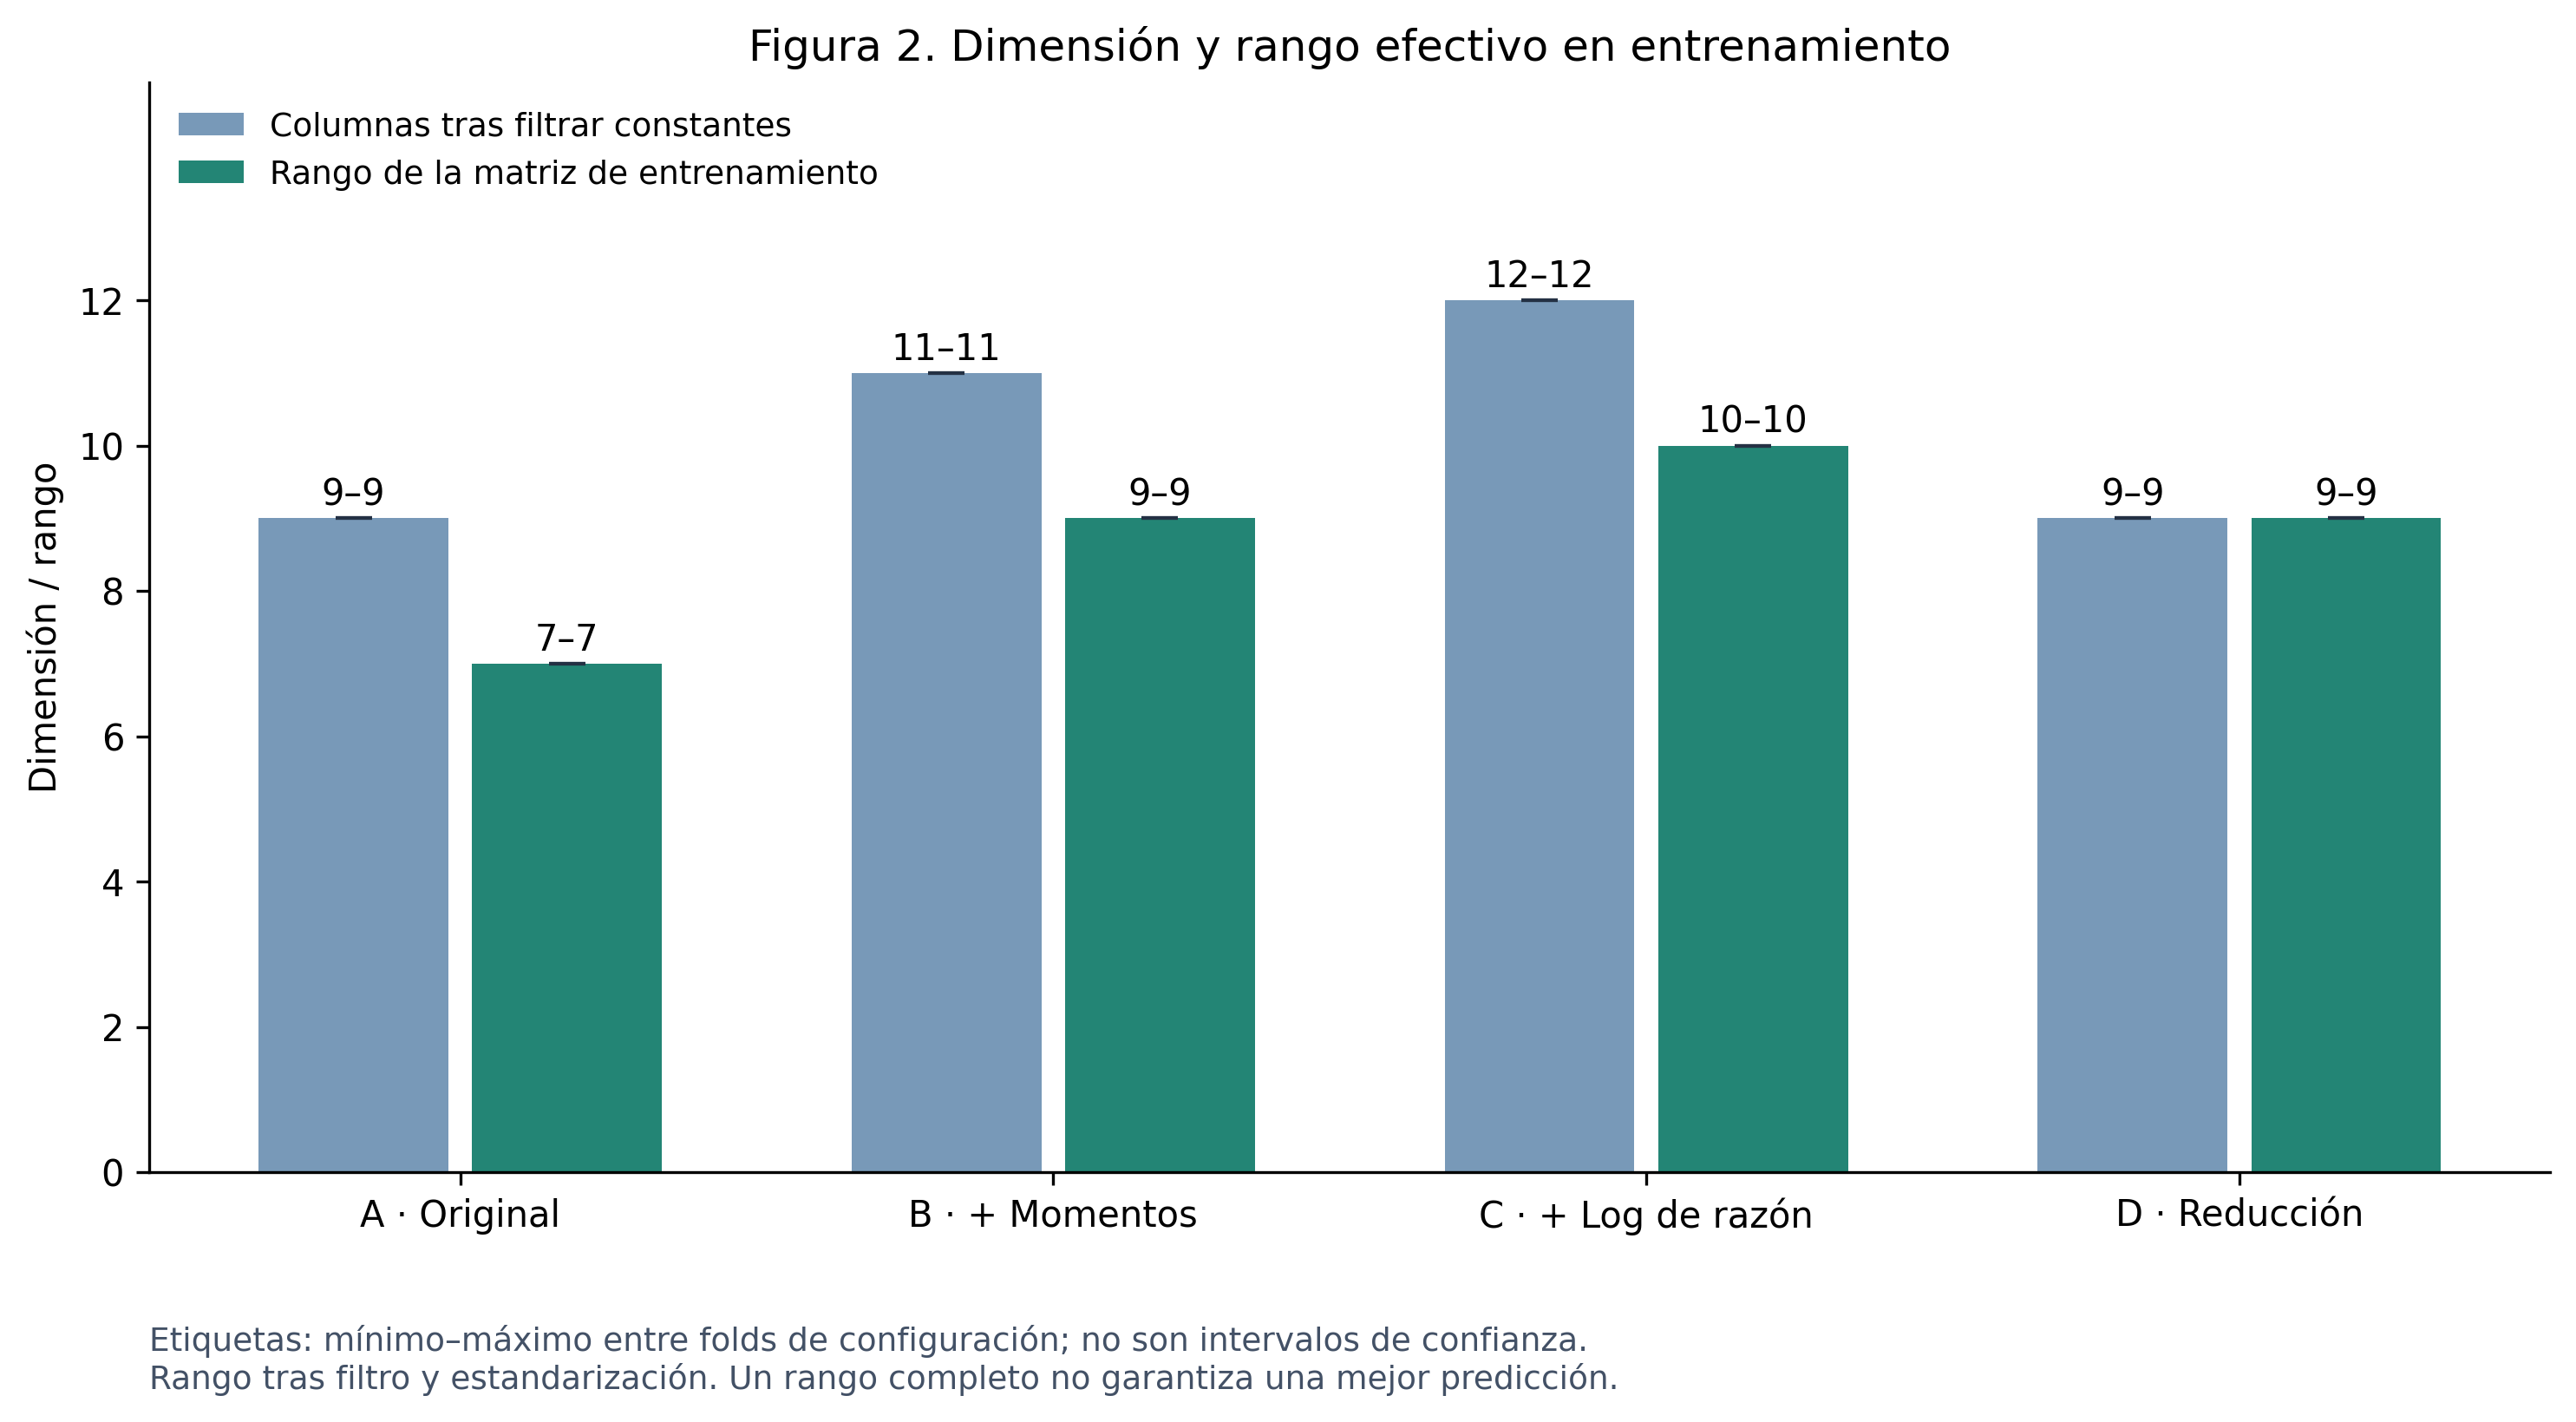

El rango se calcula después de transformar y estandarizar cada entrenamiento. Un rango menor que el número de columnas indica dependencia lineal en ese diseño. Las fórmulas no lineales pueden aumentar el rango sin aportar nuevas observaciones ni garantizar menor error.

In [7]:
show_figure('FE07_rango')

## 4.5 Auditoría de una predicción

Se reconstruye el fold que reserva el caso utilizado en 4.2. Se comprueba que todo su grupo queda fuera del entrenamiento y que el ajuste reproduce la predicción OOF guardada. La respuesta reservada se consulta únicamente para evaluar el error.

In [8]:
partitions = json.loads((OUT / 'particiones.json').read_text(encoding='utf-8'))
audits = json.loads((OUT / 'auditoria_transformaciones.json').read_text(encoding='utf-8'))
split = next(s for s in partitions
             if s['protocolo'] == 'configuracion' and case_id in s['test_cases'])
saved = next(a for a in audits if a['protocolo'] == 'configuracion'
             and a['experimento'] == 'B' and a['fold'] == split['fold'])
by_case = frame.set_index('Case_n')
train, held_out = by_case.loc[split['train_cases']], by_case.loc[split['test_cases']]
train_groups = set(nominal_groups(train, config['group_columns']))
held_out_groups = set(nominal_groups(held_out, config['group_columns']))
assert train_groups.isdisjoint(held_out_groups)

pipe = make_pipeline('B', alpha=config['model']['alpha'])
with threadpool_limits(limits=1):
    pipe.fit(train[GEOMETRY], train[TARGET])
    estimate = pipe.predict(held_out[GEOMETRY])
np.testing.assert_allclose(pipe.named_steps['imputer'].statistics_, saved['imputer_median'])
np.testing.assert_allclose(pipe.named_steps['scale'].mean_, saved['scaler_mean'])
np.testing.assert_allclose(pipe.named_steps['scale'].scale_, saved['scaler_scale'])
stored = predictions.query("protocolo == 'configuracion' and experimento == 'B'").set_index('Case_n')
np.testing.assert_allclose(estimate, stored.loc[held_out.index, 'predicho_N'], atol=1e-10)

show_table(pd.DataFrame([
    ['Fold reconstruido', str(split['fold'])],
    ['Grupo reservado (Y | altura fibra | altura pivote)', split['grupo_excluido']],
    ['Casos reservados', ', '.join(map(str, split['test_cases']))],
    ['Grupos compartidos entre train y validación', str(sorted(train_groups & held_out_groups))],
    ['Estadísticas y predicción', 'Coinciden con la ejecución guardada'],
], columns=['Comprobación', 'Resultado']))

Comprobación,Resultado
Fold reconstruido,6
Grupo reservado (Y | altura fibra | altura pivote),4|1|1
Casos reservados,1
Grupos compartidos entre train y validación,[]
Estadísticas y predicción,Coinciden con la ejecución guardada


In [9]:
names = feature_names(pipe).tolist()
raw_features = pipe[:3].transform(held_out[GEOMETRY])
z = pd.DataFrame(pipe[:-1].transform(held_out[GEOMETRY]), index=held_out.index, columns=names)
means = pd.Series(pipe.named_steps['scale'].mean_, index=names)
scales = pd.Series(pipe.named_steps['scale'].scale_, index=names)
medians = pd.Series(pipe.named_steps['imputer'].statistics_, index=GEOMETRY)
selected = ['n_cells_Y', 'Fiber_height', 'Fiber_base', *MOMENTS]
audit_view = pd.DataFrame({
    'Variable': selected,
    'Valor antes de escalar': raw_features.loc[case_id, selected].to_numpy(),
    'Mediana de imputación train': medians.reindex(selected).to_numpy(),
    'Media train': means[selected].to_numpy(),
    'Escala train': scales[selected].to_numpy(),
    'z del caso reservado': z.loc[case_id, selected].to_numpy(),
})
np.testing.assert_allclose(
    z[selected], (raw_features[selected] - means[selected]) / scales[selected])
show_table(audit_view)
display(Markdown('**z = (valor − media de train) / escala de train**. Los momentos se calculan después de imputar los ingredientes; por eso no tienen mediana de imputación propia. En esta tabla curada la geometría está completa.'))

Variable,Valor antes de escalar,Mediana de imputación train,Media train,Escala train,z del caso reservado
n_cells_Y,4.0000,5.0000,5.0800,0.7960,-1.3568
Fiber_height,1.0000,1.2000,1.2080,0.1647,-1.2627
Fiber_base,2.4000,1.6900,1.7384,0.2826,2.3413
I_fibra_bh3_mm4,0.2000,—,0.2599,0.0864,-0.6934
I_fibra_hb3_mm4,1.1520,—,0.5482,0.2312,2.6112


**z = (valor − media de train) / escala de train**. Los momentos se calculan después de imputar los ingredientes; por eso no tienen mediana de imputación propia. En esta tabla curada la geometría está completa.

In [10]:
# De las características estandarizadas a una fuerza estimada en N.
reconstructed = pipe.named_steps['model'].intercept_ + z.to_numpy() @ pipe.named_steps['model'].coef_
np.testing.assert_allclose(estimate, reconstructed, atol=1e-10)
show_table(pd.DataFrame({
    'Caso reservado': held_out.index,
    'Primera falla observada [N]': held_out[TARGET].to_numpy(),
    'Predicción B [N]': estimate,
    'Error absoluto [N]': np.abs(held_out[TARGET].to_numpy() - estimate),
}))
display(Markdown('La predicción utiliza solo la geometría. El valor observado permite medir su error; este ejemplo es una validación del modelo, no una alarma en tiempo real.'))

Caso reservado,Primera falla observada [N],Predicción B [N],Error absoluto [N]
1,47.5500,81.7562,34.2062


La predicción utiliza solo la geometría. El valor observado permite medir su error; este ejemplo es una validación del modelo, no una alarma en tiempo real.

## 4.6 Evaluación fuera de muestra

MAE es el error absoluto medio principal; RMSE penaliza más los errores grandes; MedAE resume el error absoluto mediano. Todos se expresan en N. R² se calcula sobre las predicciones OOF reunidas, no sobre folds individuales. OOF significa que cada caso fue predicho sin entrenar con su grupo nominal.

In [11]:
metric_columns = ['MAE_N', 'RMSE_N', 'MedAE_N', 'R2_OOF']
show_table(primary[metric_columns].reset_index())

experimento,MAE_N,RMSE_N,MedAE_N,R2_OOF
Dummy,56.3090,61.7164,61.3584,-0.1036
A,13.2466,16.3457,11.9409,0.9226
B,12.8346,16.2029,11.7801,0.9239
C,12.9139,16.3271,11.8643,0.9228
D,17.0350,21.1361,14.9109,0.8706


### Figura 3. Error por representación

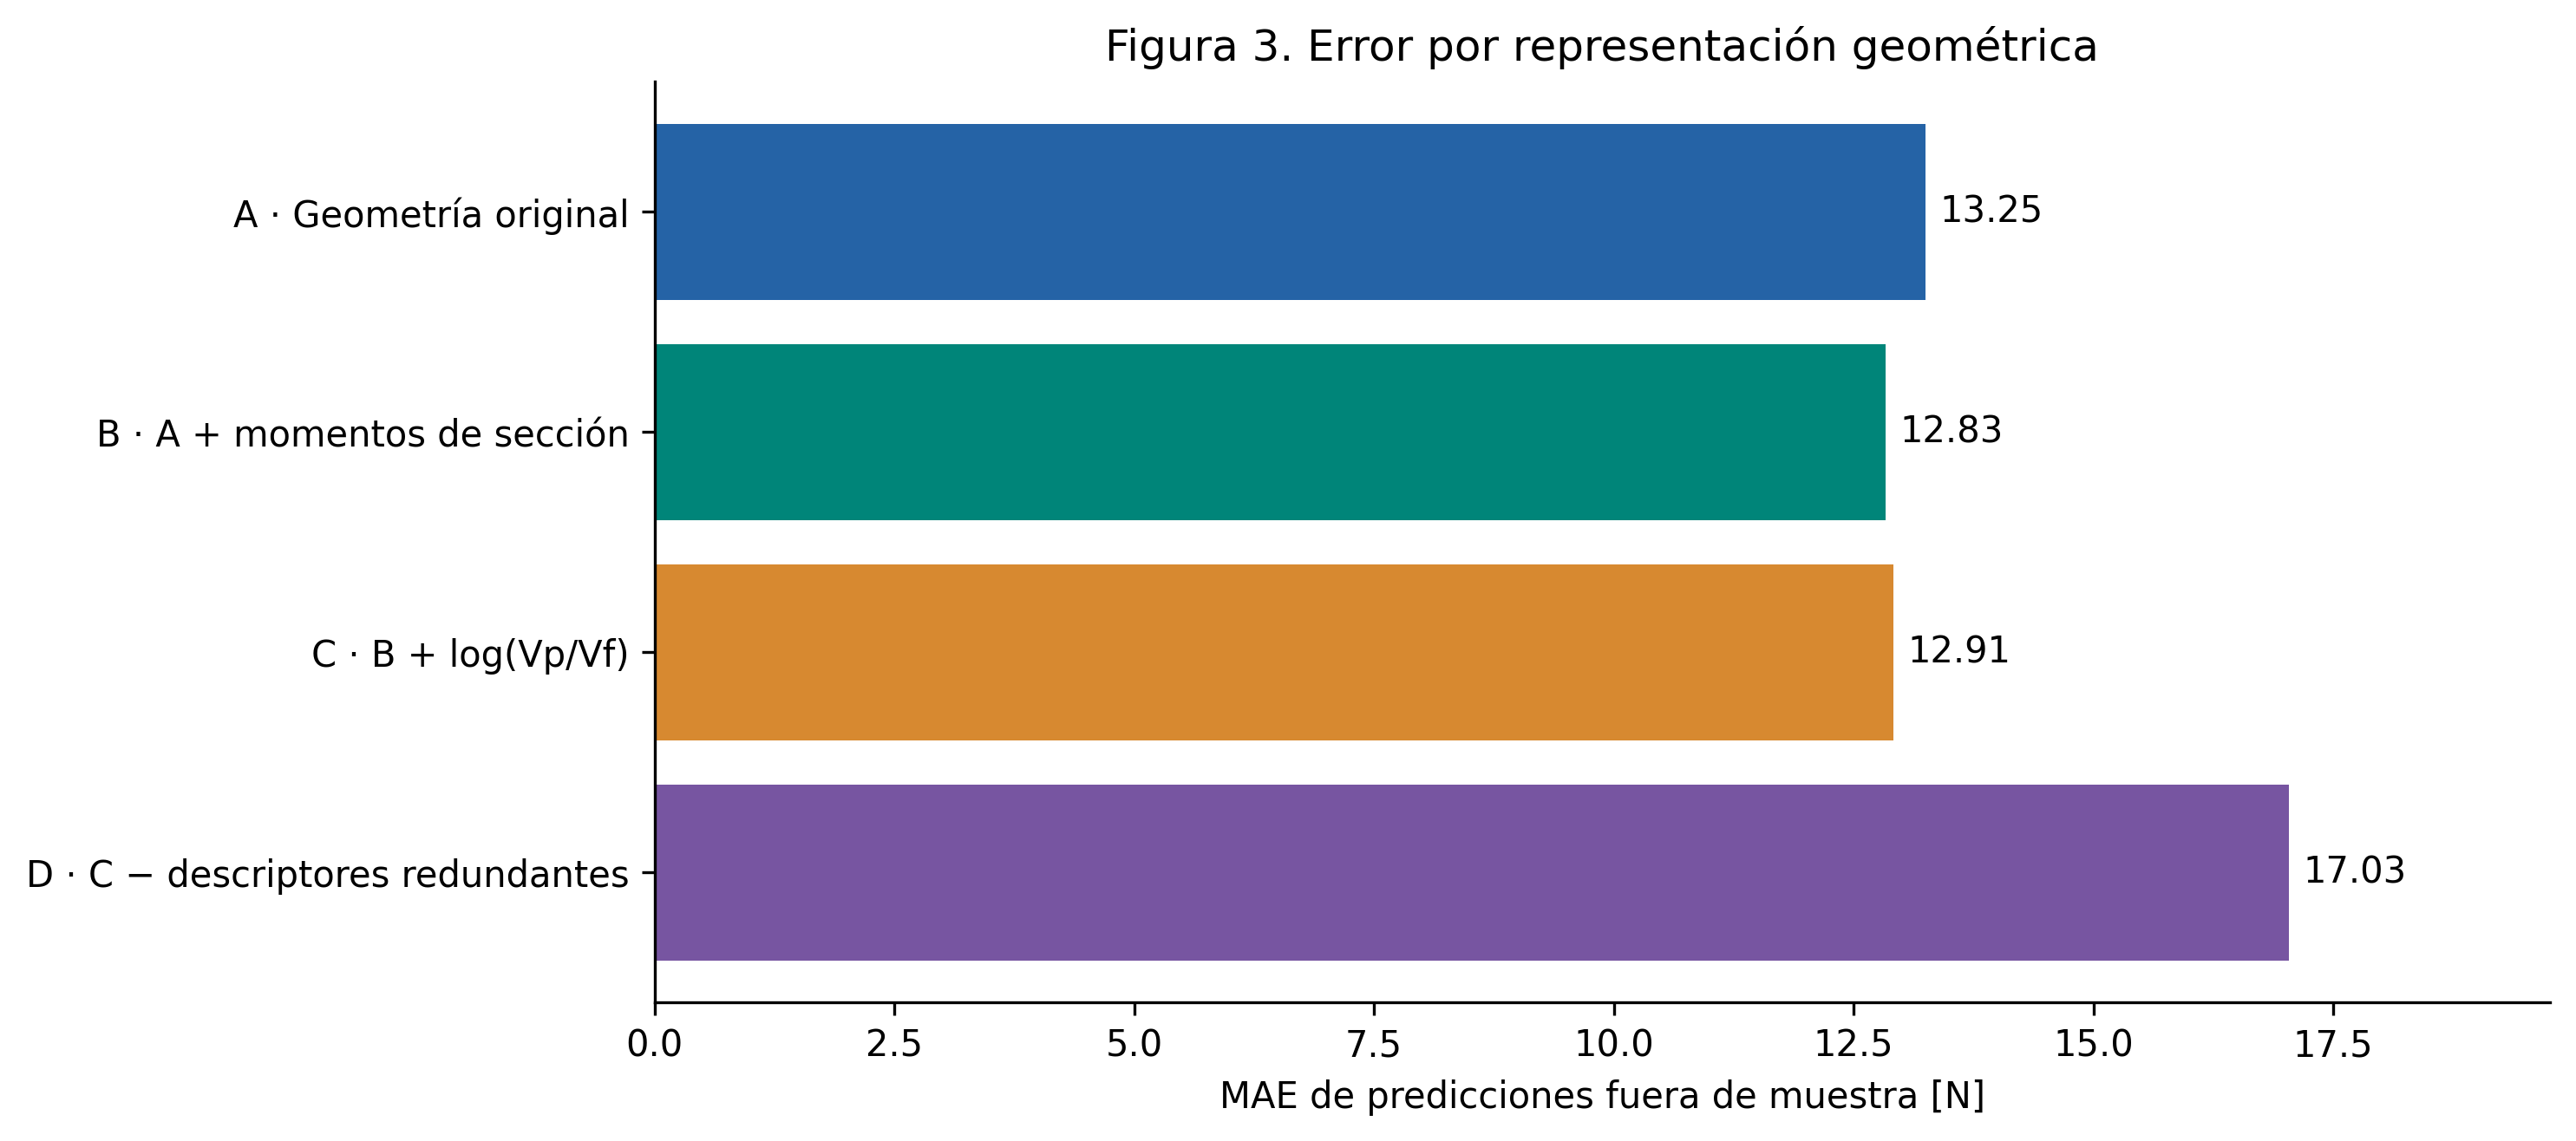

Menor MAE significa menor error medio. La dispersión entre grupos se muestra en la figura 7; estas barras no son intervalos de confianza.

In [12]:
show_figure('FE01_error')

### Figura 4. Observado frente a predicho

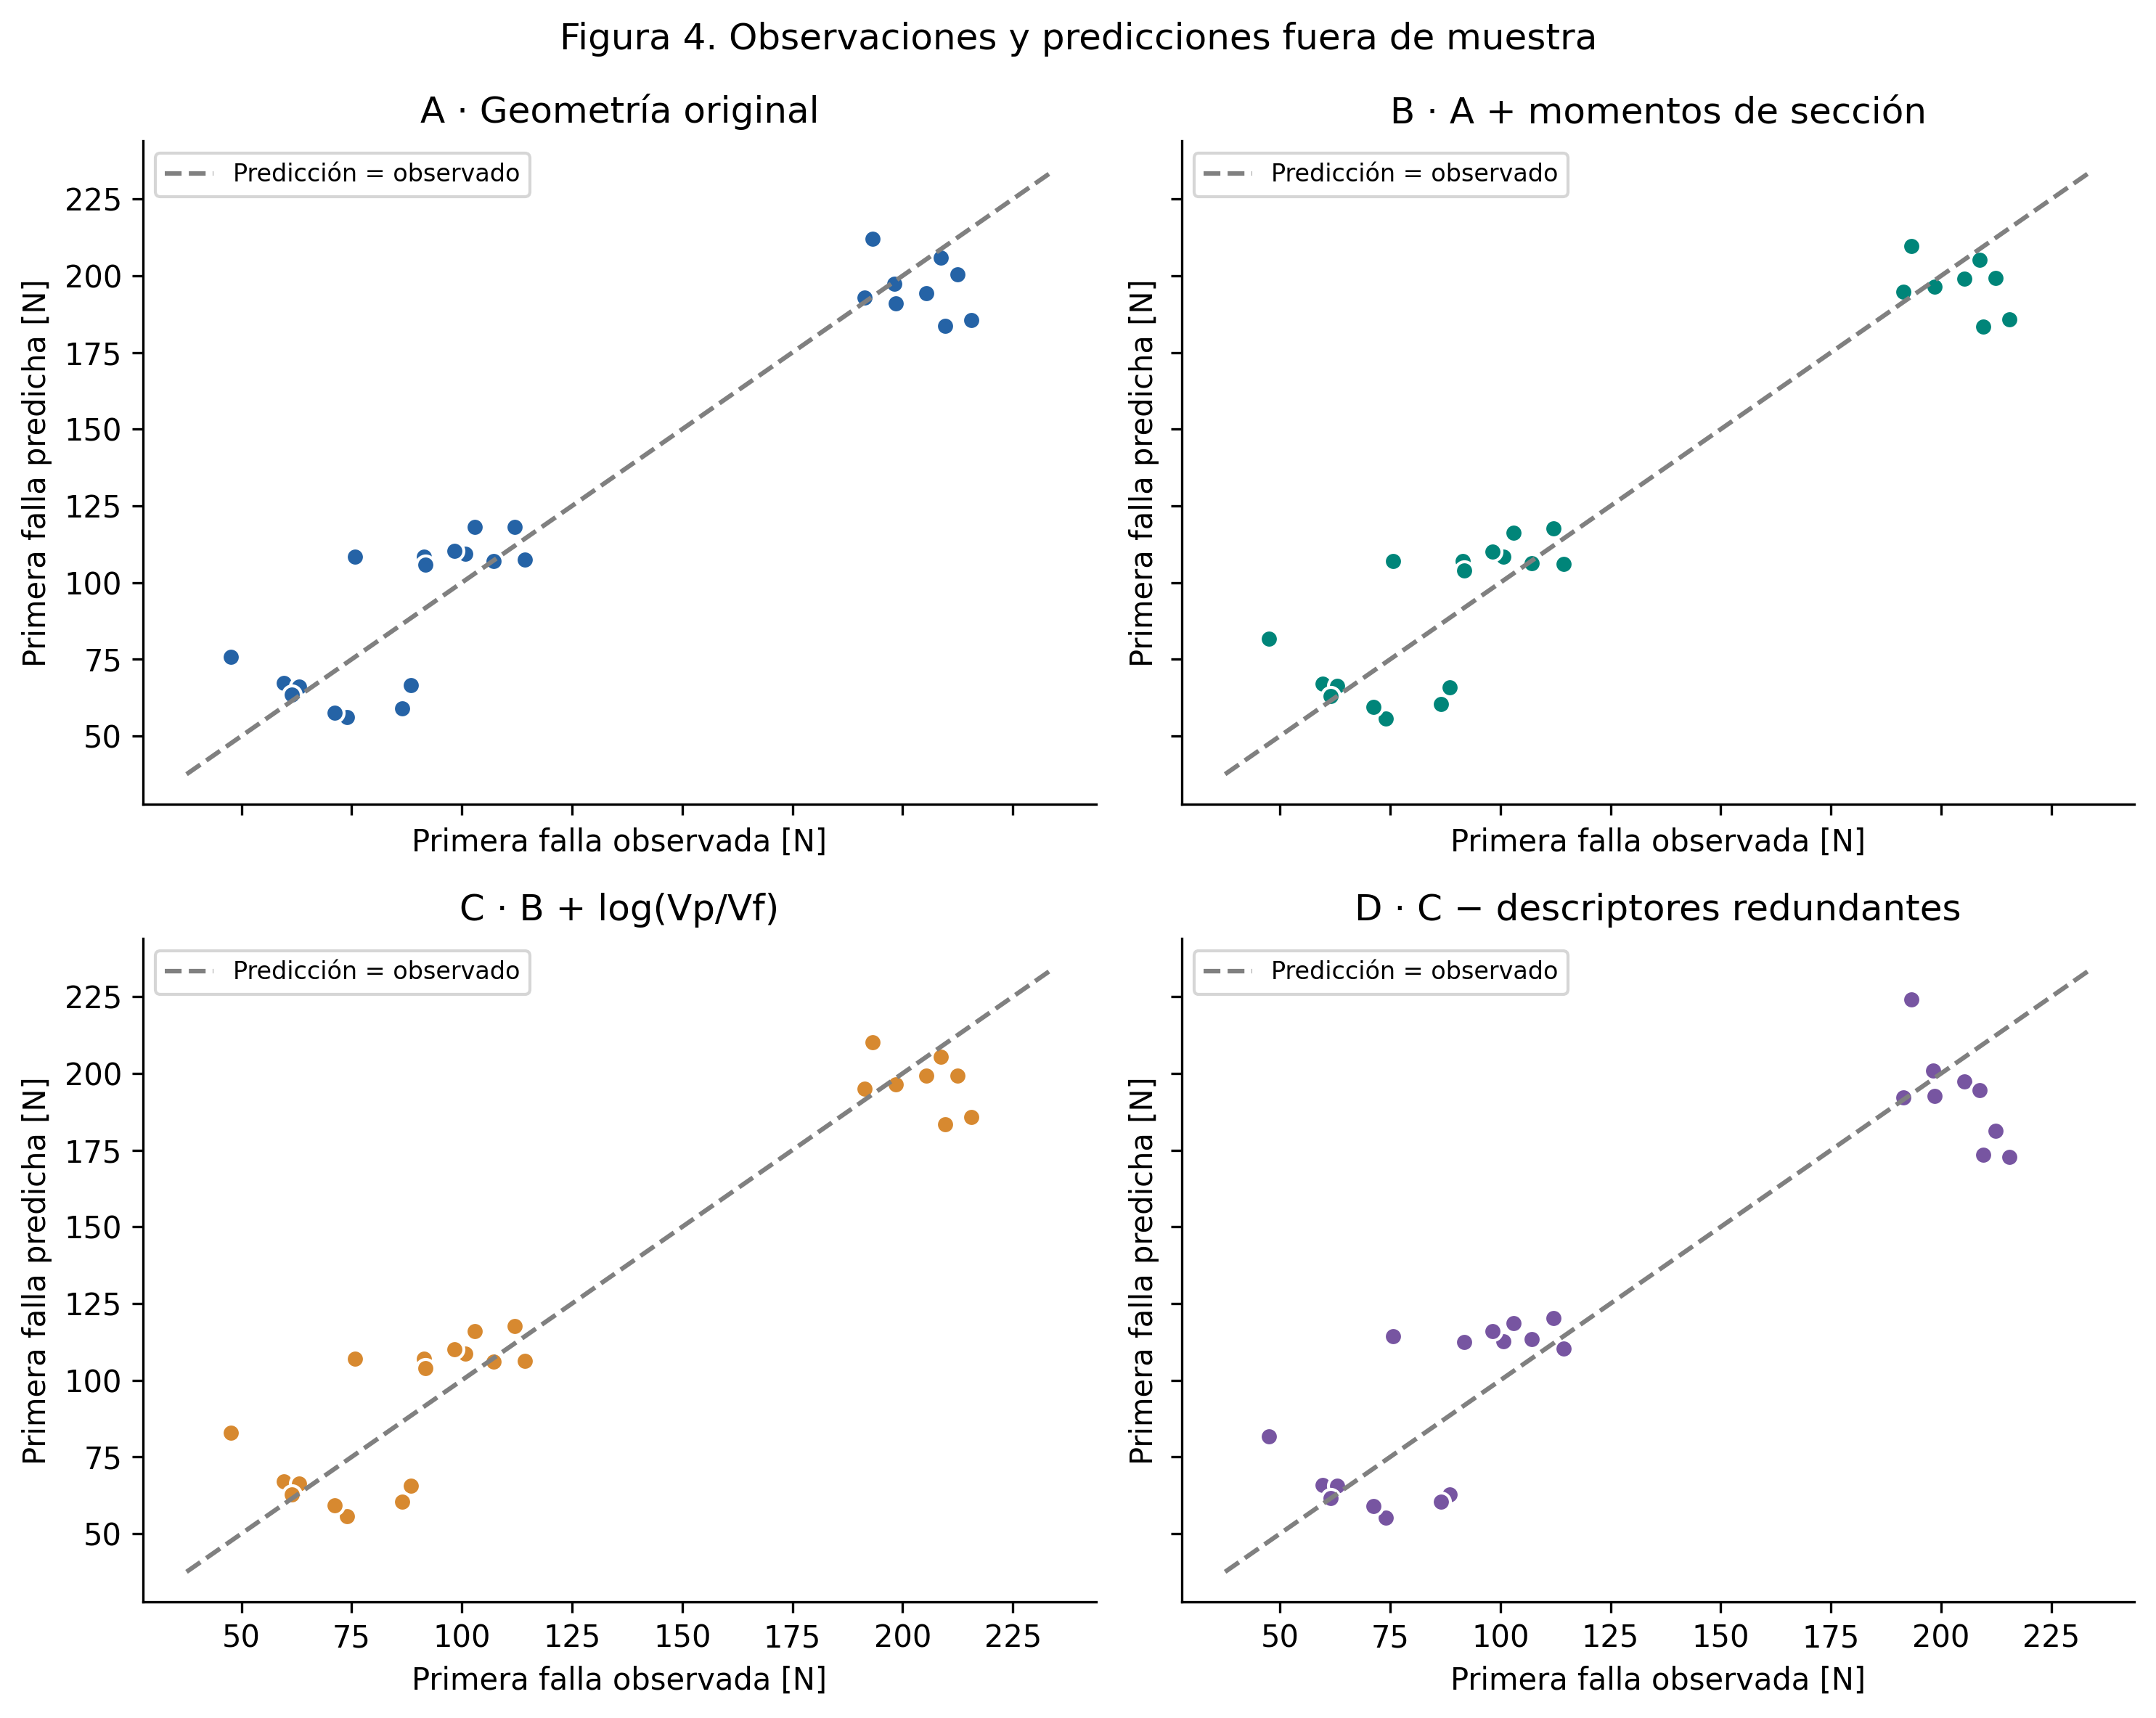

La diagonal representa coincidencia perfecta. Cada predicción procede de un modelo que no entrenó con esa configuración nominal.

In [13]:
show_figure('FE02_observado_predicho')

### Figura 5. Residuales

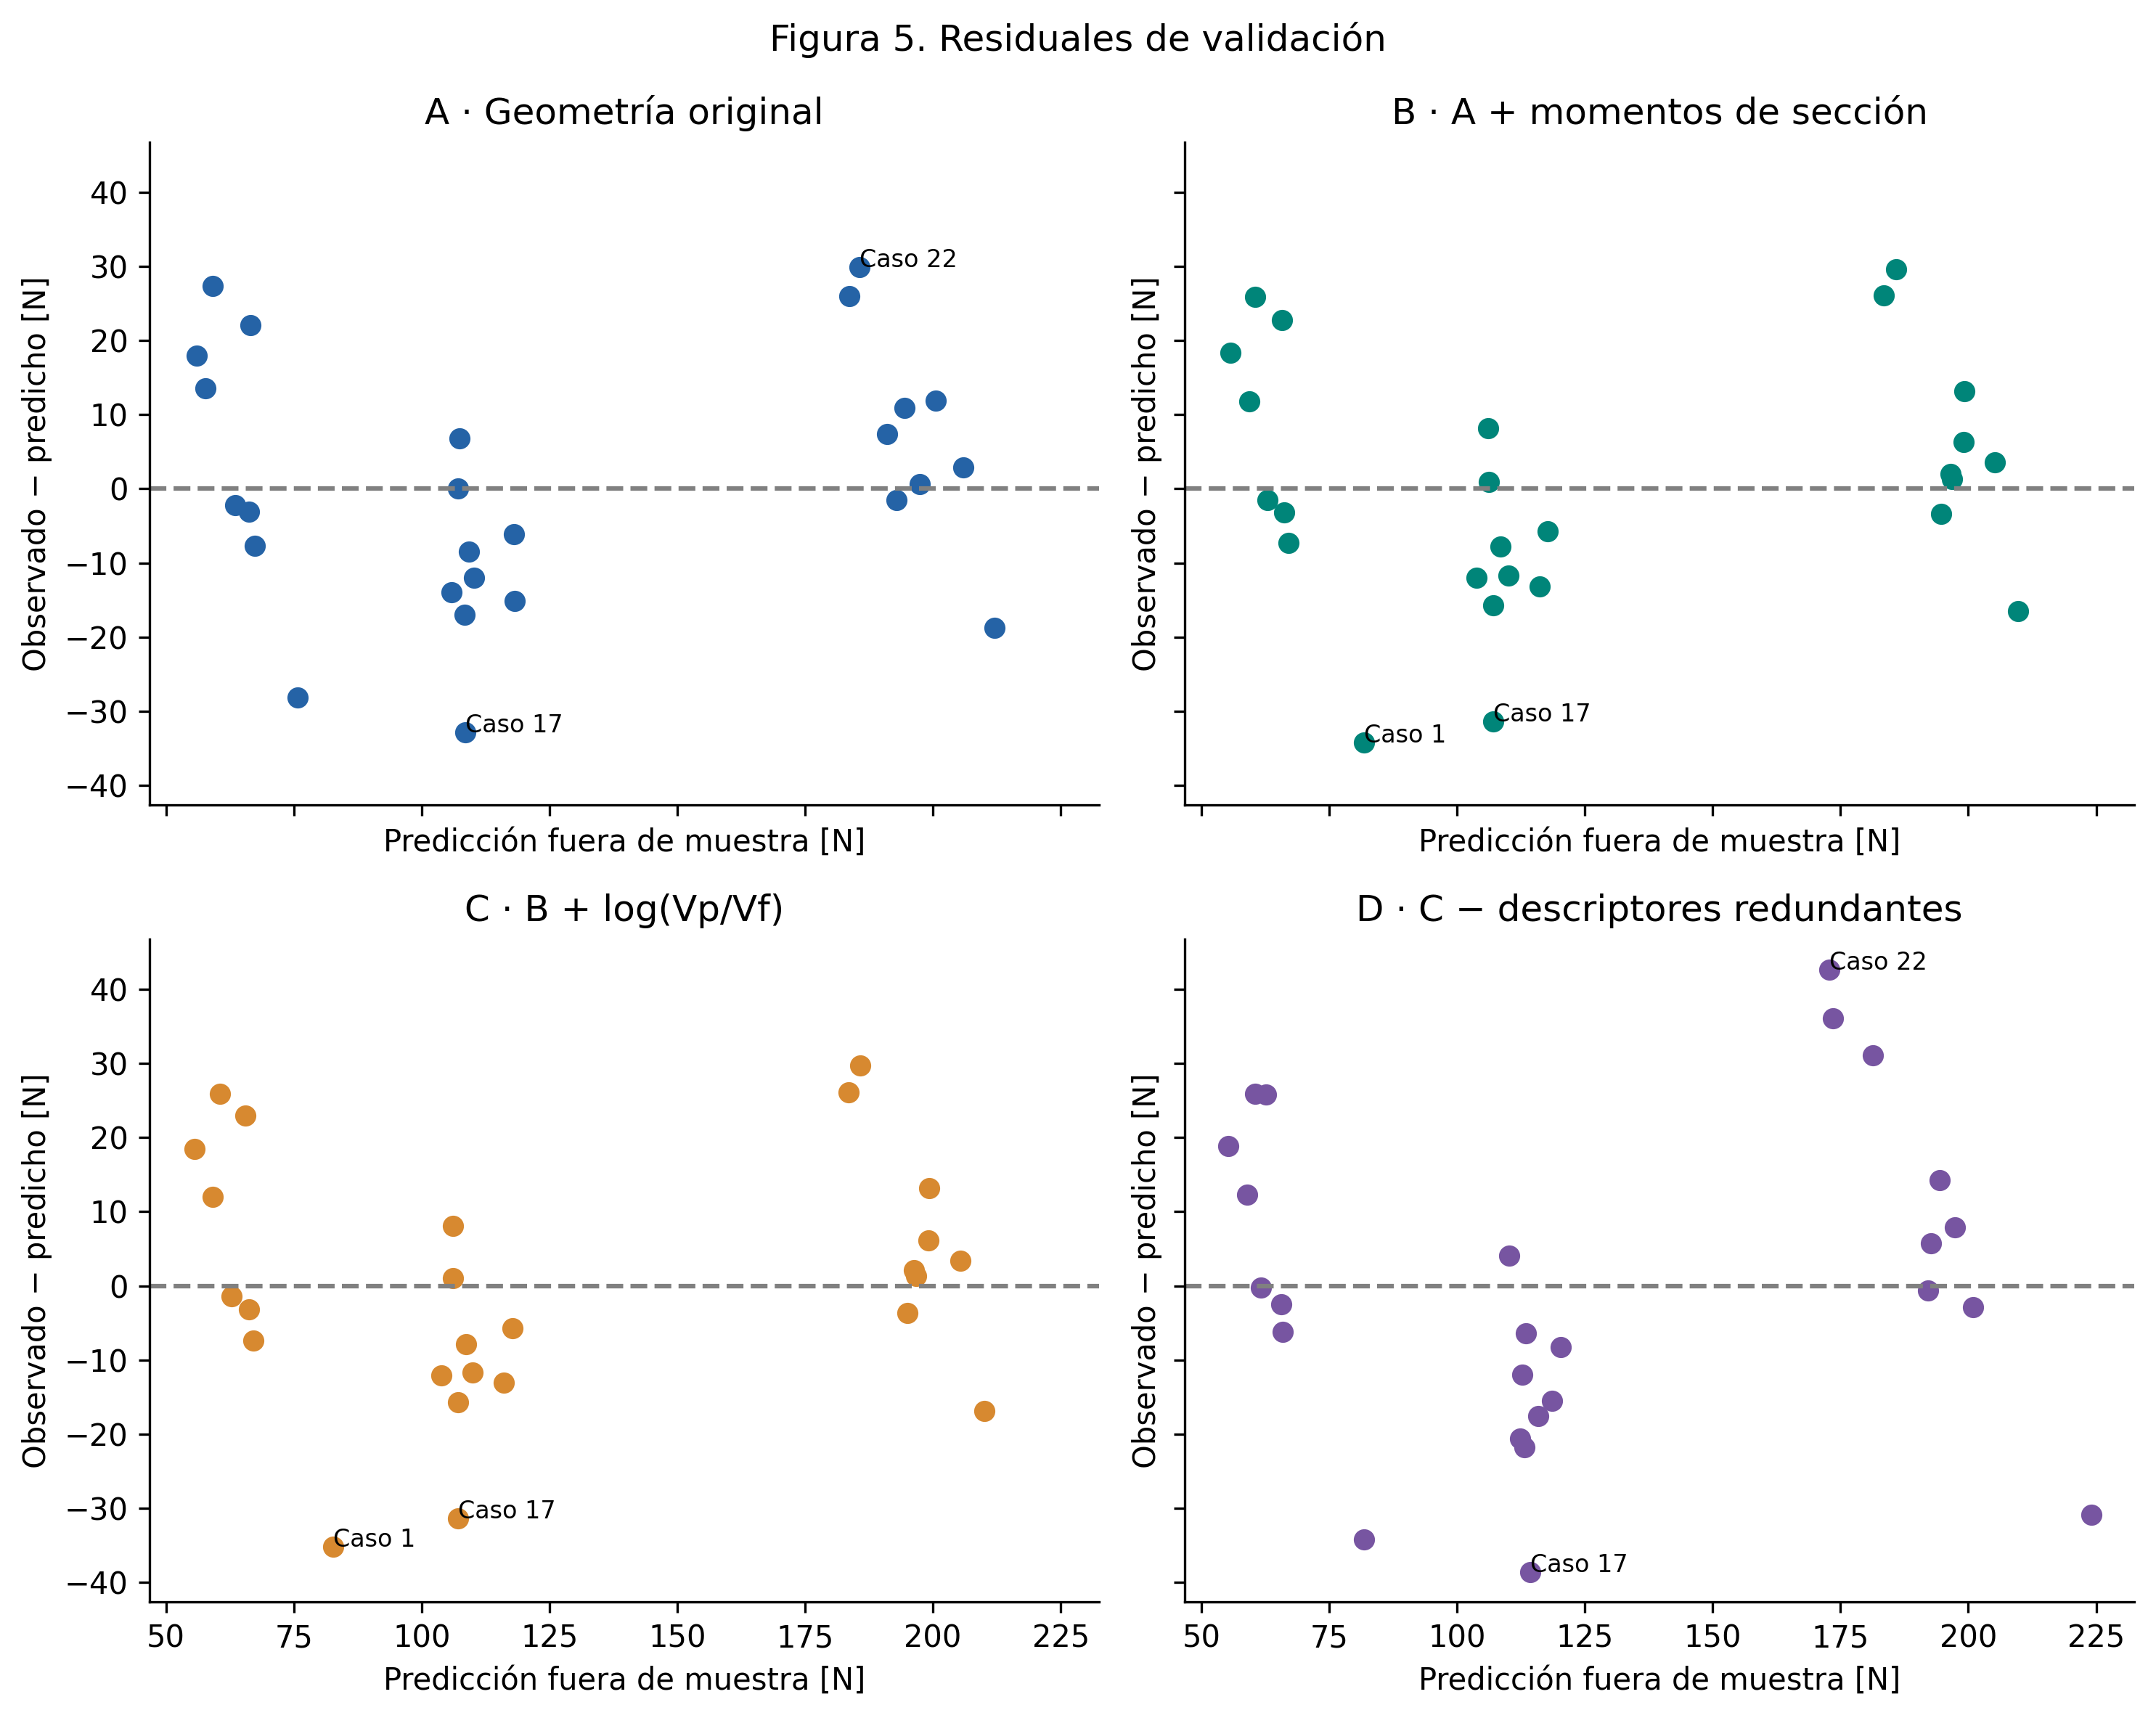

Residual = observado − predicho: positivo indica subestimación. Los casos señalados tienen los mayores errores absolutos; no se eliminan.

In [14]:
show_figure('FE03_residuos')

In [15]:
# Errores más grandes de B: conservar trazabilidad, sin eliminar observaciones.
principal_b = predictions.query("protocolo == 'configuracion' and experimento == 'B'")
worst = principal_b.nlargest(3, 'error_absoluto_N')
show_table(worst[['Case_n', 'familia', 'observado_N', 'predicho_N', 'residuo_N', 'error_absoluto_N']])
display(Markdown('Los mayores errores señalan dónde revisar la predicción; por sí solos no demuestran un dato erróneo ni justifican eliminarlo.'))

Case_n,familia,observado_N,predicho_N,residuo_N,error_absoluto_N
1,4,47.5500,81.7562,-34.2062,34.2062
17,5,75.7100,107.1136,-31.4036,31.4036
22,6,215.5200,185.8802,29.6398,29.6398


Los mayores errores señalan dónde revisar la predicción; por sí solos no demuestran un dato erróneo ni justifican eliminarlo.

## 4.7 Familias y alcance de generalización

La validación principal reserva una configuración. La prueba adicional reserva toda una familia `n_cells_Y`: obliga a estimar una arquitectura no vista. Las dos preguntas se evalúan por separado.

### Figura 6. Error por familia

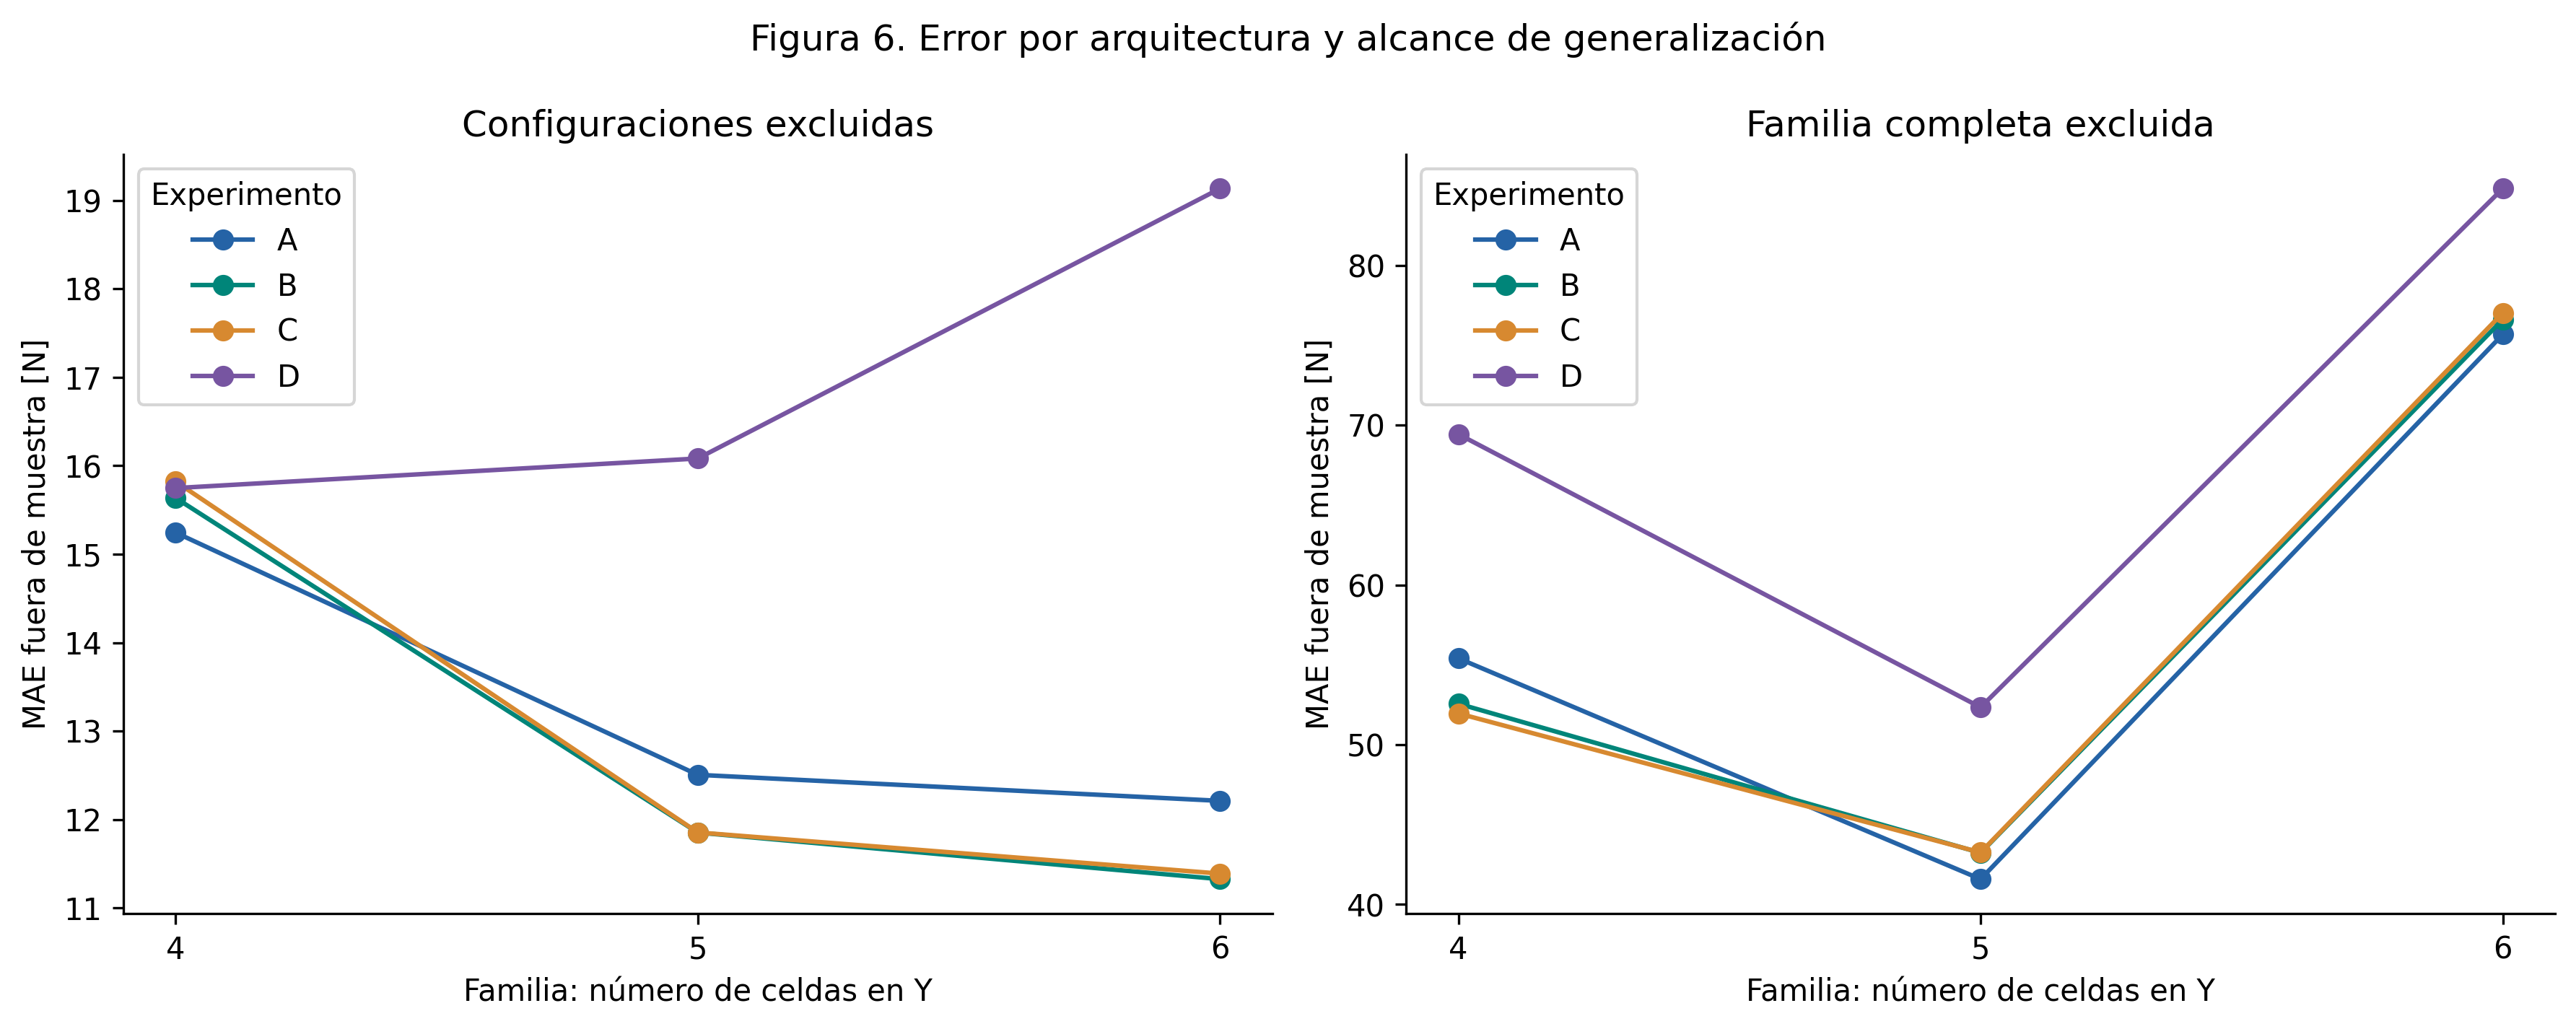

En la validación por configuración, B mejora frente a A en Y=5 y Y=6, pero empeora en Y=4. Excluir una familia completa aumenta mucho el error: generalizar a otra arquitectura sigue sin resolverse.

In [16]:
show_figure('FE04_error_familia')

In [17]:
family = table('errores_familia')
family_ab = family.query("protocolo == 'configuracion' and experimento in ['A', 'B']").pivot(
    index='familia', columns='experimento', values='MAE_N')
family_ab['ΔMAE B − A [N]'] = family_ab.B - family_ab.A
family_ab['Cambio con B'] = np.where(family_ab['ΔMAE B − A [N]'] < 0, 'Mejora', 'Empeora')
show_table(family_ab.rename(columns={'A': 'MAE A [N]', 'B': 'MAE B [N]'}).reset_index())
display(Markdown('**Prueba adicional: familia completa excluida.**'))
show_table(secondary[metric_columns + ['predicciones_negativas']].reset_index())
display(Markdown('B mejora el error agregado de configuraciones, pero no en todas las familias. Las fuerzas negativas de D en la prueba adicional son físicamente inadmisibles y se conservan para documentar el fallo de extrapolación.'))

familia,MAE A [N],MAE B [N],ΔMAE B − A [N],Cambio con B
4,15.2443,15.6359,0.3916,Empeora
5,12.5058,11.8527,-0.6531,Mejora
6,12.2115,11.3265,-0.8850,Mejora


**Prueba adicional: familia completa excluida.**

experimento,MAE_N,RMSE_N,MedAE_N,R2_OOF,predicciones_negativas
Dummy,80.5926,87.5214,84.3917,-1.2194,0
A,57.6374,60.4281,64.5196,-0.0580,0
B,57.6538,60.4740,61.7609,-0.0596,0
C,57.6190,60.5277,61.6351,-0.0615,0
D,68.8341,71.2923,72.5589,-0.4726,4


B mejora el error agregado de configuraciones, pero no en todas las familias. Las fuerzas negativas de D en la prueba adicional son físicamente inadmisibles y se conservan para documentar el fallo de extrapolación.

## 4.8 Ablaciones y sensibilidad

Cada intervención se compara con su referencia: B−A, C−B y D−C. Un ΔMAE negativo favorece la intervención. La omisión de scores estudia cuánto contribuyen al error agregado; no retira esos casos del entrenamiento ni vuelve a ajustar el modelo.

### Figura 7. Aporte de cada intervención

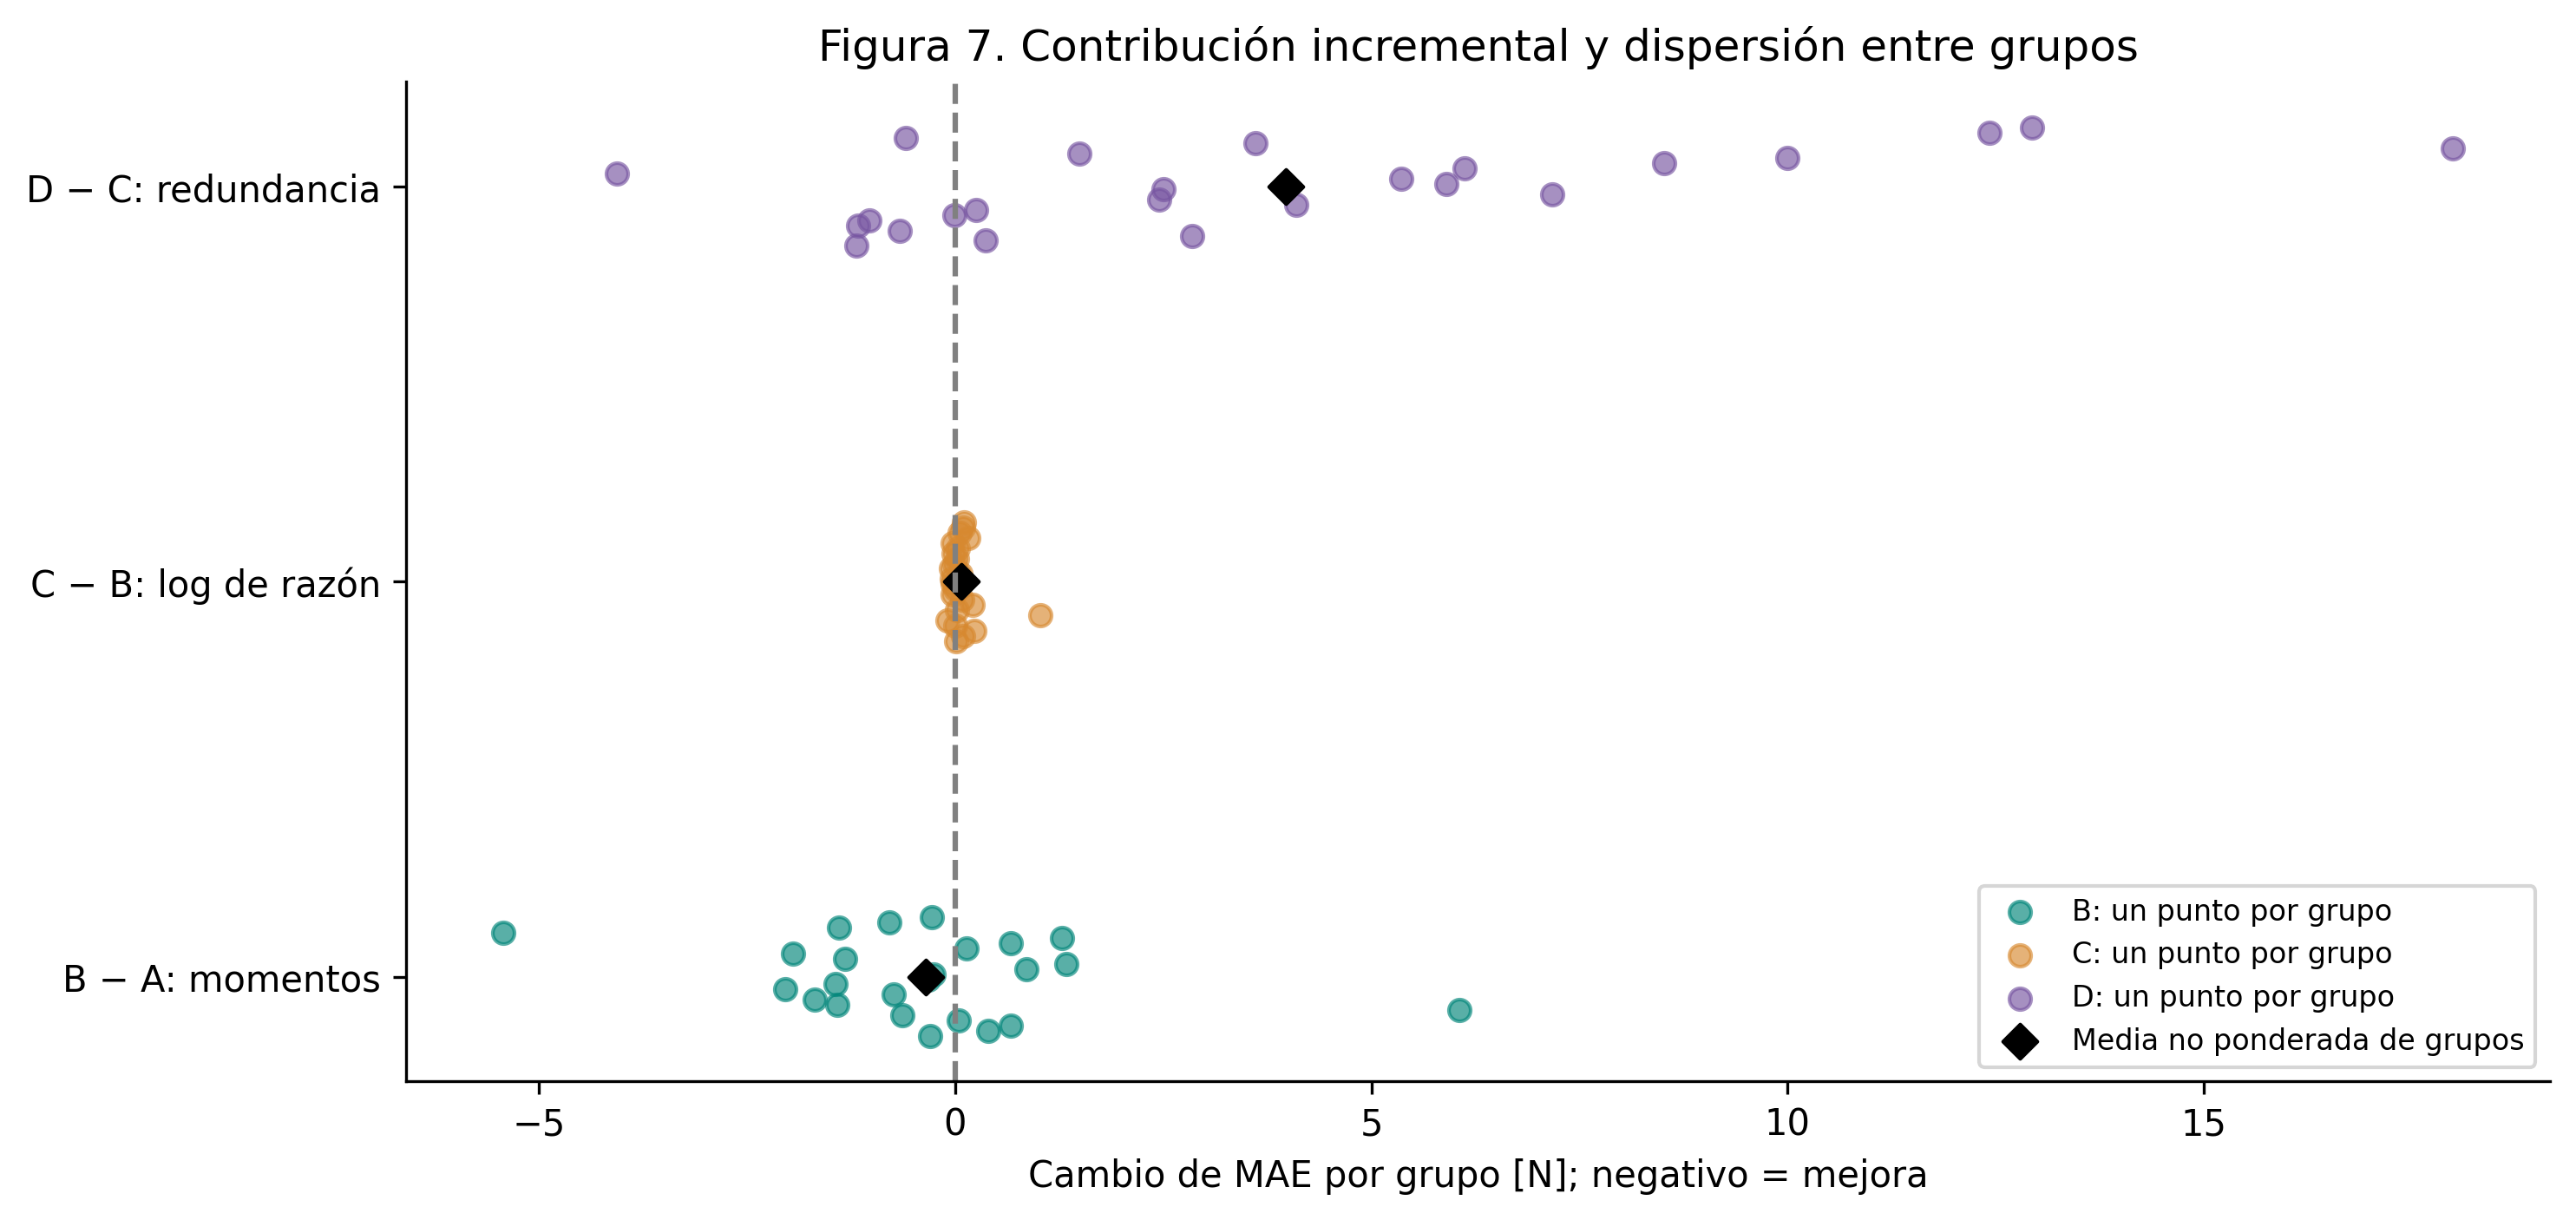

Cada punto es el cambio de MAE de un grupo; negativo indica mejora. El rombo es la media de grupos, no ponderada por casos. No mide importancia causal individual.

In [18]:
show_figure('FE05_ablaciones')

In [19]:
decisions = table('decisiones')
show_table(decisions[['experimento', 'referencia', 'delta_MAE_N', 'delta_RMSE_N',
                      'fraccion_grupos_mejora', 'decision']])
sensitivity = table('sensibilidad_scores')
scenarios = sensitivity.loc[~sensitivity.escenario.str.startswith('omitir_score_grupo_')]
show_table(scenarios[['experimento', 'escenario', 'delta_MAE_N']])

experimento,referencia,delta_MAE_N,delta_RMSE_N,fraccion_grupos_mejora,decision
B,A,-0.4119,-0.1429,0.6250,Mantener en evaluación
C,B,0.0792,0.1242,0.3750,Descartar
D,C,4.1211,4.8090,0.2917,Descartar


experimento,escenario,delta_MAE_N
B,todos,-0.4119
B,sin_scores_Cook_1_3,-0.7267
B,sin_scores_revision_pivote,-0.4524
C,todos,0.0792
C,sin_scores_Cook_1_3,0.0338
C,sin_scores_revision_pivote,0.0755
D,todos,4.1211
D,sin_scores_Cook_1_3,4.3889
D,sin_scores_revision_pivote,3.2033


In [20]:
# ¿Depende el signo de la mejora de un único grupo de validación?
leave_one_score = sensitivity.loc[sensitivity.escenario.str.startswith('omitir_score_grupo_')]
score_range = leave_one_score.groupby(['experimento', 'referencia']).delta_MAE_N.agg(
    minimo='min', maximo='max').reset_index()
score_range['Signo al omitir cualquier grupo'] = np.where(
    score_range.maximo < 0, 'Siempre mejora',
    np.where(score_range.minimo > 0, 'Siempre empeora', 'Cambia de signo'))
show_table(score_range.rename(columns={'minimo': 'ΔMAE mínimo [N]', 'maximo': 'ΔMAE máximo [N]'}))
display(Markdown('Estos rangos son diagnósticos de contribución al score, no intervalos de confianza ni validación independiente.'))

experimento,referencia,ΔMAE mínimo [N],ΔMAE máximo [N],Signo al omitir cualquier grupo
B,A,-0.6708,-0.2115,Siempre mejora
C,B,0.0417,0.0862,Siempre empeora
D,C,3.4288,4.5140,Siempre empeora


Estos rangos son diagnósticos de contribución al score, no intervalos de confianza ni validación independiente.

## 4.9 Interpretación de resultados

In [21]:
# Aplicación visible de las reglas declaradas; no se decide por el menor MAE solamente.
rule = config['decision_rule']
b_result = decisions.set_index('experimento').loc['B']
requirements = pd.DataFrame([
    ['Reducción de MAE (%)', f">= {rule['adopt_min_mae_reduction_percent']:g}",
     b_result.reduccion_MAE_pct, b_result.reduccion_MAE_pct >= rule['adopt_min_mae_reduction_percent']],
    ['Grupos con menor error (%)', f">= {100 * rule['adopt_min_group_win_fraction']:g}",
     100 * b_result.fraccion_grupos_mejora, b_result.fraccion_grupos_mejora >= rule['adopt_min_group_win_fraction']],
    ['ΔRMSE frente a A [N]', '<= 0', b_result.delta_RMSE_N, b_result.delta_RMSE_N <= 0],
    ['ΔMAE en familias excluidas [N]', '<= 0', b_result.delta_MAE_familia_N,
     b_result.delta_MAE_familia_N <= 0],
], columns=['Criterio para adoptar B', 'Regla', 'Resultado', 'Cumple'])
show_table(requirements)

best = primary.loc[list('ABCD'), 'MAE_N'].idxmin()
delta_b = primary.loc['B', 'MAE_N'] - primary.loc['A', 'MAE_N']
display(Markdown(
    f'**Momentos de sección:** B obtiene MAE {primary.loc["B", "MAE_N"]:.2f} N '
    f'(Δ frente a A: {delta_b:.3f} N). La mejora es pequeña y desigual por familia; '
    'cumple solo parte de las reglas, por lo que se mantiene en evaluación.'))
display(Markdown(
    '**Razón y reducción:** añadir ln(Vp/Vf) no mejora B. Retirar el bloque geométrico empeora C. '
    'Redundancia algebraica no implica una eliminación inocua: también cambia la penalización efectiva de Ridge.'))
display(Markdown(
    f'**Generalización:** al excluir familias completas, el MAE de B es {secondary.loc["B", "MAE_N"]:.2f} N. '
    'El EDA ya examinó el mismo conjunto; esta comparación es exploratoria. '
    'Corresponde confirmar A y B con geometrías conciliadas y ensayos independientes antes de plantear su uso predictivo.'))

Criterio para adoptar B,Regla,Resultado,Cumple
Reducción de MAE (%),>= 5,3.1097,False
Grupos con menor error (%),>= 60,62.5000,True
ΔRMSE frente a A [N],<= 0,-0.1429,True
ΔMAE en familias excluidas [N],<= 0,0.0164,False


**Momentos de sección:** B obtiene MAE 12.83 N (Δ frente a A: -0.412 N). La mejora es pequeña y desigual por familia; cumple solo parte de las reglas, por lo que se mantiene en evaluación.

**Razón y reducción:** añadir ln(Vp/Vf) no mejora B. Retirar el bloque geométrico empeora C. Redundancia algebraica no implica una eliminación inocua: también cambia la penalización efectiva de Ridge.

**Generalización:** al excluir familias completas, el MAE de B es 57.65 N. El EDA ya examinó el mismo conjunto; esta comparación es exploratoria. Corresponde confirmar A y B con geometrías conciliadas y ensayos independientes antes de plantear su uso predictivo.

## 4.10 Artefactos y control de integridad

In [22]:
from src.ingesta import sha256_file
manifest = json.loads((OUT / 'manifest.json').read_text(encoding='utf-8'))
assert all(sha256_file(ROOT / p) == digest for p, digest in manifest['inputs_sha256'].items())
assert all(sha256_file(OUT / p) == digest for p, digest in manifest['artifacts_sha256'].items())
display(Markdown(
    '**Integridad comprobada.** Resultados en `reports/feature_engineering/`: '
    '[predicciones OOF](../reports/feature_engineering/tables/predicciones_oof.csv), '
    '[métricas](../reports/feature_engineering/tables/comparacion_experimentos.csv), '
    '[particiones](../reports/feature_engineering/particiones.json) y '
    '[estadísticas de entrenamiento](../reports/feature_engineering/auditoria_transformaciones.json).'))

**Integridad comprobada.** Resultados en `reports/feature_engineering/`: [predicciones OOF](../reports/feature_engineering/tables/predicciones_oof.csv), [métricas](../reports/feature_engineering/tables/comparacion_experimentos.csv), [particiones](../reports/feature_engineering/particiones.json) y [estadísticas de entrenamiento](../reports/feature_engineering/auditoria_transformaciones.json).